In [1]:
import pandas as pd
import os

files = [f for f in os.listdir('/content')
         if f.endswith(('.xlsx', '.xls', '.csv'))]

print("Available files:", files)

Available files: ['online_retail_II.xlsx']


In [3]:
file_name = files[0]

df = pd.read_excel(file_name)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (525461, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:

# Step 4: Clean the dataset
df.columns = df.columns.str.strip()

# Convert InvoiceDate into date format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Remove rows with missing essential values
df = df.dropna(subset=[
    "Customer ID", "Invoice", "InvoiceDate", "Quantity", "Price"
]).copy()

# Remove cancelled invoices (invoice numbers starting with C)
df = df[~df["Invoice"].astype(str).str.startswith("C")].copy()

# Remove invalid quantities and prices
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()

# Calculate purchase revenue
df["Revenue"] = df["Quantity"] * df["Price"]

print("Cleaning completed!")
print("Rows after cleaning:", df.shape[0])
print("\nMissing values:")
print(df[["Customer ID", "InvoiceDate", "Quantity", "Price"]].isnull().sum())

display(df.head())


Cleaning completed!
Rows after cleaning: 407664

Missing values:
Customer ID    0
InvoiceDate    0
Quantity       0
Price          0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [5]:

# Step 5: Calculate RFM values

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Average purchase value per invoice
rfm["AveragePurchaseValue"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

# Historical total spend (proxy, not predictive lifetime value)
rfm["CustomerLifetimeValue"] = rfm["Monetary"]

print("RFM analysis completed!")
print("Total customers:", len(rfm))

display(rfm.head())

print("\nRFM Descriptive Statistics:")
display(
    rfm[[
        "Recency",
        "Frequency",
        "Monetary",
        "AveragePurchaseValue",
        "CustomerLifetimeValue"
    ]].describe().round(2)
)


RFM analysis completed!
Total customers: 4312


,Customer ID,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue
0,12346.0,165,11,372.86,33.896364,372.86
1,12347.0,3,2,1323.32,661.660000,1323.32
2,12348.0,74,1,222.16,222.160000,222.16
3,12349.0,43,3,2671.14,890.380000,2671.14
4,12351.0,11,1,300.93,300.930000,300.93



RFM Descriptive Statistics:


,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue
count,4312.00,4312.00,4312.00,4312.00,4312.00
mean,91.17,4.46,2048.24,378.32,2048.24
std,96.86,8.17,8914.48,492.56,8914.48
min,1.00,1.00,2.95,2.95,2.95
25%,18.00,1.00,307.99,182.09,307.99
50%,53.00,2.00,706.02,287.37,706.02
75%,136.00,5.00,1723.14,423.58,1723.14
max,374.00,205.00,349164.35,11880.84,349164.35


In [6]:

# Step 6: Standardise the RFM features

from sklearn.preprocessing import StandardScaler

features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardisation completed!")
print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

print("\nFirst 5 scaled rows:")
display(pd.DataFrame(X_scaled, columns=features).head())


Standardisation completed!
Original data shape: (4312, 3)
Scaled data shape: (4312, 3)

First 5 scaled rows:


,Recency,Frequency,Monetary
0,0.762299,0.801087,-0.187961
1,-0.910402,-0.300603,-0.081329
2,-0.177305,-0.423013,-0.204868
3,-0.497389,-0.178193,0.069883
4,-0.827799,-0.423013,-0.196031


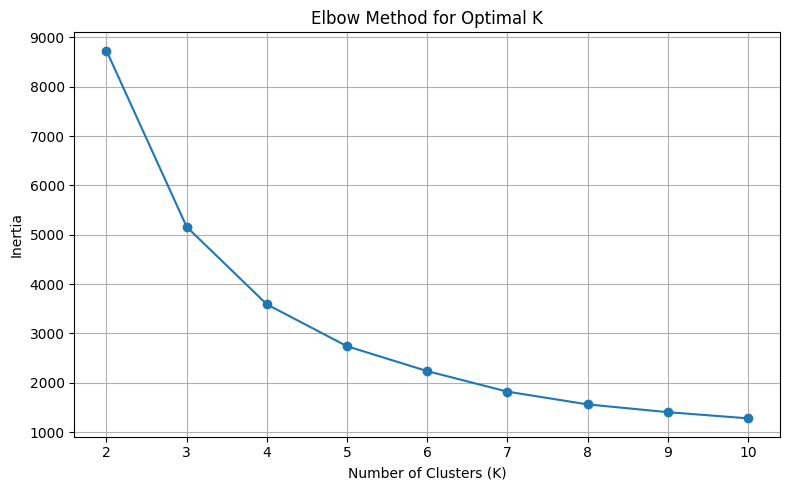

In [7]:

# Step 7: Find the optimal number of clusters

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

# Step 8: Apply K-Means clustering

k = 4  # Update this after checking the Elbow graph

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("Number of clusters:", k)
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head(10))


K-Means clustering completed!
Number of clusters: 4

Customers in each cluster:
Cluster
0    3201
1    1047
2       5
3      59
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue,Cluster
0,12346.0,165,11,372.86,33.896364,372.86,1
1,12347.0,3,2,1323.32,661.660000,1323.32,0
2,12348.0,74,1,222.16,222.160000,222.16,0
3,12349.0,43,3,2671.14,890.380000,2671.14,0
4,12351.0,11,1,300.93,300.930000,300.93,0
5,12352.0,11,2,343.80,171.900000,343.80,0
6,12353.0,44,1,317.76,317.760000,317.76,0
7,12355.0,203,1,488.21,488.210000,488.21,1
8,12356.0,16,3,3562.25,1187.416667,3562.25,0
9,12357.0,24,2,12079.99,6039.995000,12079.99,0


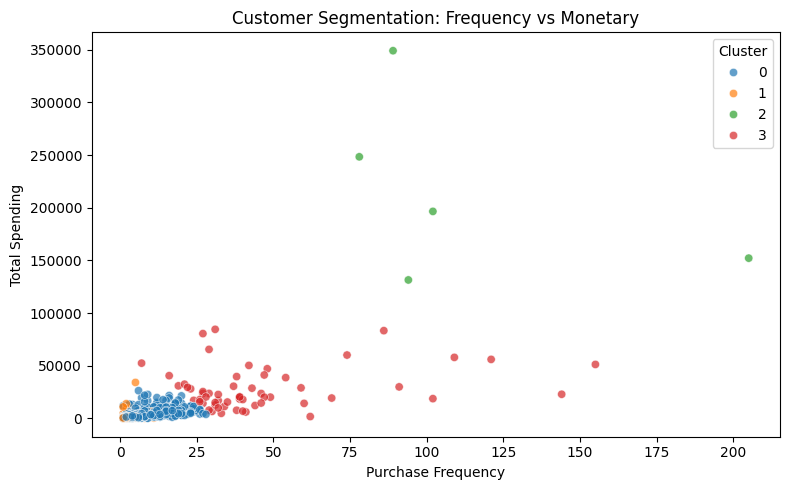

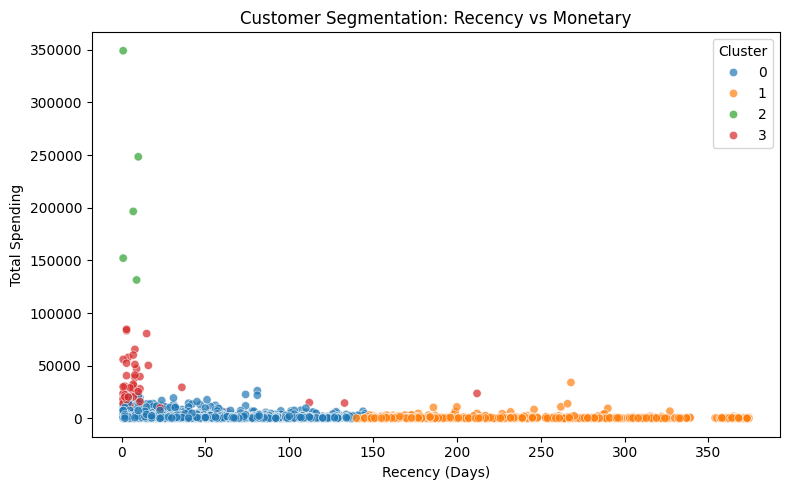

In [9]:

# Step 9: Visualise customer clusters

import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Frequency vs Monetary
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

# Plot 2: Recency vs Monetary
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()


CUSTOMER CLUSTER PROFILES


,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,AvgPurchaseValue,AvgHistoricalSpend
Cluster,,,,,,
0,3201,43.07,4.43,1710.80,377.73,1710.80
1,1047,242.98,1.66,596.88,345.32,596.88
2,5,5.60,113.60,215543.67,2235.08,215543.67
3,59,14.27,46.03,28018.43,838.91,28018.43


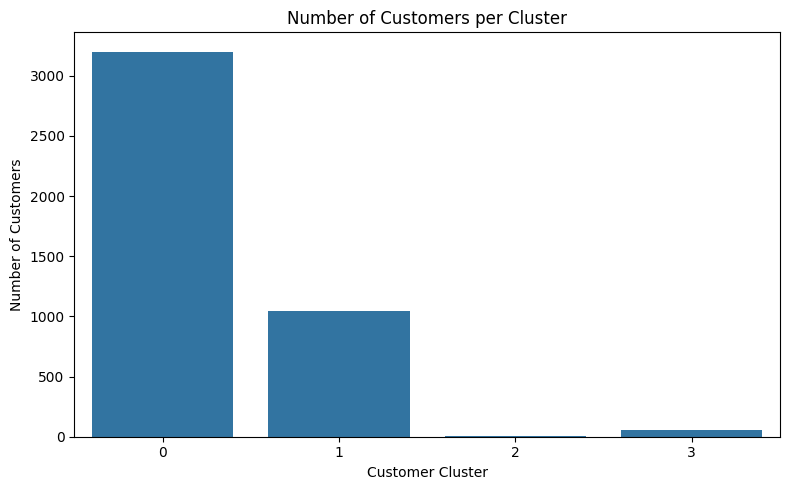

In [10]:

# Step 10: Create cluster profiles

profile = rfm.groupby("Cluster").agg(
    CustomerCount=("Customer ID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    AvgPurchaseValue=("AveragePurchaseValue", "mean"),
    AvgHistoricalSpend=("CustomerLifetimeValue", "mean")
).round(2)

print("CUSTOMER CLUSTER PROFILES")
display(profile)

# Bar chart: number of customers in each cluster
plt.figure(figsize=(8, 5))

sns.barplot(
    x=profile.index.astype(str),
    y=profile["CustomerCount"]
)

plt.title("Number of Customers per Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [11]:

# Step 11: Marketing recommendations for each cluster

overall_recency = rfm["Recency"].median()
overall_frequency = rfm["Frequency"].median()
overall_monetary = rfm["Monetary"].median()

print("CUSTOMER SEGMENT INSIGHTS AND MARKETING STRATEGIES")

for cluster_id, row in profile.iterrows():
    print(f"\n--- Cluster {cluster_id} ---")
    print(f"Number of customers: {int(row['CustomerCount'])}")
    print(f"Average recency: {row['AvgRecency']:.2f} days")
    print(f"Average frequency: {row['AvgFrequency']:.2f}")
    print(f"Average spending: {row['AvgMonetary']:.2f}")

    if (
        row["AvgRecency"] <= overall_recency
        and row["AvgFrequency"] >= overall_frequency
        and row["AvgMonetary"] >= overall_monetary
    ):
        print("Customer type: Active, frequent, high-spending")
        print("Marketing: Loyalty rewards, VIP offers and retention campaigns.")

    elif row["AvgRecency"] > overall_recency:
        print("Customer type: Less recently active customers")
        print("Marketing: Win-back emails, personalised discounts and reminders.")

    elif row["AvgFrequency"] >= overall_frequency:
        print("Customer type: Repeat customers")
        print("Marketing: Membership benefits, cross-selling and referral offers.")

    else:
        print("Customer type: Lower-frequency or developing customers")
        print("Marketing: Welcome offers, product recommendations and targeted promotions.")


CUSTOMER SEGMENT INSIGHTS AND MARKETING STRATEGIES

--- Cluster 0 ---
Number of customers: 3201
Average recency: 43.07 days
Average frequency: 4.43
Average spending: 1710.80
Customer type: Active, frequent, high-spending
Marketing: Loyalty rewards, VIP offers and retention campaigns.

--- Cluster 1 ---
Number of customers: 1047
Average recency: 242.98 days
Average frequency: 1.66
Average spending: 596.88
Customer type: Less recently active customers
Marketing: Win-back emails, personalised discounts and reminders.

--- Cluster 2 ---
Number of customers: 5
Average recency: 5.60 days
Average frequency: 113.60
Average spending: 215543.67
Customer type: Active, frequent, high-spending
Marketing: Loyalty rewards, VIP offers and retention campaigns.

--- Cluster 3 ---
Number of customers: 59
Average recency: 14.27 days
Average frequency: 46.03
Average spending: 28018.43
Customer type: Active, frequent, high-spending
Marketing: Loyalty rewards, VIP offers and retention campaigns.


In [12]:

# Step 12: Save final project results

rfm.to_csv(
    "KathelienPrisca_Task2_CustomerSegments.csv",
    index=False
)

profile.to_csv(
    "KathelienPrisca_Task2_ClusterProfiles.csv"
)

print("Final result files saved successfully!")
print("1. Customer Segments CSV")
print("2. Cluster Profiles CSV")


Final result files saved successfully!
1. Customer Segments CSV
2. Cluster Profiles CSV
